# Shape Classification with MMM (MedicalMultiTaskModeling)

Uses the `NativeBlocks` MMM encoder to classify shape images against a `labels.csv` ground-truth file.

**Requires Python 3.11 and the `mmm` conda env.**

**Expected `labels.csv` format:**
```
image_name,label
circle_001.png,circle
square_042.png,square
```

## 1. Install

ModuleNotFoundError: No module named 'mmm'

In [2]:
!/opt/conda/envs/mmm/bin/pip install medicalmultitaskmodeling[interactive] numpy pandas matplotlib Pillow scikit-learn -q
print('Done')

Done


## 2. Imports

In [7]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms

WROK_DIR = "/home/jovyan/sparse-auto-encoder" # or your own

os.chdir(WROK_DIR)
os.environ["MMM_LICENSE_ACCEPTED"] = "i accept"

try:

    from mmm.labelstudio_ext.NativeBlocks import NativeBlocks, MMM_MODELS, DEFAULT_MODEL
    print("✅ MMM imported successfully")
    print(f"Available models: {list(MMM_MODELS.keys())}")
    print(f"Default model: {DEFAULT_MODEL}")
except ImportError as e:
    print(f"❌ MMM import failed: {e}")

print(f"PyTorch: {torch.__version__}")
print(f"CUDA: {torch.cuda.is_available()}")
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")


✅ MMM imported successfully
Available models: ['encoder-1.0.4.pt.zip']
Default model: encoder-1.0.4.pt.zip
PyTorch: 2.1.2+cu121
CUDA: True
Device: cuda


## 3. Configuration

In [8]:
# ── Edit these ────────────────────────────────────────────────
IMAGE_DIR   = "./shapes_data"
LABELS_CSV  = "./labels.csv"
OUTPUT_CSV  = "./predictions.csv"

SHAPE_CLASSES = [
    "circle", "square", "triangle", "rectangle",
    "pentagon", "hexagon", "star", "ellipse",
]
# ──────────────────────────────────────────────────────────────

NUM_CLASSES = len(SHAPE_CLASSES)
IMAGE_SIZE  = 224
BATCH_SIZE  = 16

image_dir  = Path(IMAGE_DIR)
labels_csv = Path(LABELS_CSV)

assert image_dir.exists(),  f"Image directory not found: {image_dir}"
assert labels_csv.exists(), f"Labels CSV not found: {labels_csv}"
print(f"Image dir : {image_dir.resolve()}")
print(f"Labels CSV: {labels_csv.resolve()}")


Image dir : /home/jovyan/sparse-auto-encoder/shapes_data
Labels CSV: /home/jovyan/sparse-auto-encoder/labels.csv


## 4. Load Labels CSV

In [9]:
labels_df = pd.read_csv(labels_csv)
labels_df.columns = [c.strip().lower() for c in labels_df.columns]

name_col  = next((c for c in labels_df.columns if any(x in c for x in ['image','file','name'])), labels_df.columns[0])
label_col = next((c for c in labels_df.columns if any(x in c for x in ['label','class'])),       labels_df.columns[1])

labels_df = labels_df.rename(columns={name_col: 'image_name', label_col: 'label'})
label_map = dict(zip(labels_df['image_name'], labels_df['label']))

print(f"Loaded {len(label_map)} entries | classes: {sorted(labels_df['label'].unique())}")
labels_df.head()


Loaded 1000 entries | classes: ['circle', 'square', 'triangle']


,image_name,label
0,shapes_data/shape_1.png,triangle
1,shapes_data/shape_2.png,triangle
2,shapes_data/shape_3.png,circle
3,shapes_data/shape_4.png,circle
4,shapes_data/shape_5.png,circle


## 5. Discover Images

In [10]:
SUPPORTED_EXTS = {'.png', '.jpg', '.jpeg', '.bmp', '.tiff', '.tif', '.webp'}
image_paths = sorted([p for p in image_dir.iterdir() if p.suffix.lower() in SUPPORTED_EXTS])
print(f"Found {len(image_paths)} images")

missing = [p.name for p in image_paths if p.name not in label_map]
if missing:
    print(f"⚠️  {len(missing)} images not in labels.csv — will still be classified")


Found 1000 images
⚠️  1000 images not in labels.csv — will still be classified


## 6. Load MMM Model

In [14]:
# Check where MMM looks for the cached model
from mmm.labelstudio_ext.NativeBlocks import MMM_MODELS, DEFAULT_MODEL
print(MMM_MODELS[DEFAULT_MODEL])

https://owncloud.fraunhofer.de/index.php/s/Q5o1uD5eHL7tr3X/download


In [15]:
# Downloads automatically on first run (~few GB)
model    = NativeBlocks(MMM_MODELS[DEFAULT_MODEL], device_identifier=str(DEVICE))
encoder  = model["encoder"]
squeezer = model["squeezer"]

# Sanity check + get embedding dim
with torch.inference_mode():
    dummy          = torch.rand(1, 3, IMAGE_SIZE, IMAGE_SIZE).to(model.device)
    feature_pyramid = encoder(dummy)
    hidden         = nn.Flatten(1)(squeezer(feature_pyramid)[1])

EMBED_DIM = hidden.shape[-1]
print(f"✅ Encoder ready | embedding dim: {EMBED_DIM}")

# Linear classification head (random weights — fine-tune or load checkpoint)
clf_head = nn.Linear(EMBED_DIM, NUM_CLASSES).to(model.device)
# clf_head.load_state_dict(torch.load('clf_head.pth'))  # ← load fine-tuned weights here
clf_head.eval()
print(f"Classification head: {EMBED_DIM} → {NUM_CLASSES}")


100%|██████████| 365M/365M [01:34<00:00, 4.05MB/s] 
ERROR:root:Did not load /tmp/tmp3ey2b9n9/fcosfpn.pt due to No module named 'mmdet'
2026-02-19 10:08:02.521 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


✅ Encoder ready | embedding dim: 512
Classification head: 512 → 8


## 7. Preprocessing Pipeline

In [16]:
preprocess = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std =[0.229, 0.224, 0.225]),
])

def load_image(path: Path) -> torch.Tensor:
    return preprocess(Image.open(path).convert('RGB'))

print("Preprocessing pipeline ready.")


Preprocessing pipeline ready.


## 8. Run Inference

In [17]:
results = []

def chunked(lst, n):
    for i in range(0, len(lst), n):
        yield lst[i:i+n]

print(f"Running inference on {len(image_paths)} images...")

with torch.inference_mode():
    for batch_paths in chunked(image_paths, BATCH_SIZE):
        tensors, valid_paths = [], []
        for p in batch_paths:
            try:
                tensors.append(load_image(p)); valid_paths.append(p)
            except Exception as e:
                print(f"  ⚠️  {p.name}: {e}")
        if not tensors:
            continue

        batch_tensor    = torch.stack(tensors).to(model.device)
        feature_pyramid = encoder(batch_tensor)
        hidden          = nn.Flatten(1)(squeezer(feature_pyramid)[1])
        logits          = clf_head(hidden)
        probs           = F.softmax(logits, dim=-1).cpu().numpy()

        for path, prob_vec in zip(valid_paths, probs):
            pred_idx   = int(np.argmax(prob_vec))
            pred_label = SHAPE_CLASSES[pred_idx]
            confidence = float(prob_vec[pred_idx])
            gt_label   = label_map.get(path.name, 'N/A')
            correct    = (pred_label == gt_label) if gt_label != 'N/A' else None
            results.append({
                'image_name': path.name, 'ground_truth': gt_label,
                'prediction': pred_label, 'confidence': round(confidence, 4), 'correct': correct,
                **{f'p_{cls}': round(float(p), 4) for cls, p in zip(SHAPE_CLASSES, prob_vec)},
            })

results_df = pd.DataFrame(results)
print(f"\n✅ Done. {len(results_df)} images processed.")
results_df.head(10)


Running inference on 1000 images...

✅ Done. 1000 images processed.


,image_name,ground_truth,prediction,confidence,correct,p_circle,p_square,p_triangle,p_rectangle,p_pentagon,p_hexagon,p_star,p_ellipse
0,shape_1.png,N/A,star,0.1724,None,0.0774,0.0787,0.1116,0.1328,0.1146,0.1721,0.1724,0.1405
1,shape_10.png,N/A,hexagon,0.1840,None,0.1105,0.0950,0.1059,0.1527,0.0960,0.1840,0.1301,0.1258
2,shape_100.png,N/A,hexagon,0.1689,None,0.0937,0.0829,0.1179,0.1378,0.1049,0.1689,0.1506,0.1434
3,shape_1000.png,N/A,hexagon,0.1793,None,0.0998,0.0775,0.1204,0.1398,0.1192,0.1793,0.1334,0.1305
4,shape_101.png,N/A,hexagon,0.1693,None,0.1058,0.0867,0.1110,0.1241,0.1006,0.1693,0.1539,0.1486
5,shape_102.png,N/A,hexagon,0.1729,None,0.0822,0.0768,0.1040,0.1424,0.1160,0.1729,0.1645,0.1412
6,shape_103.png,N/A,star,0.1960,None,0.0848,0.0799,0.1046,0.1266,0.0995,0.1429,0.1960,0.1657
7,shape_104.png,N/A,hexagon,0.1736,None,0.0882,0.0915,0.1110,0.1598,0.1060,0.1736,0.1394,0.1304
8,shape_105.png,N/A,ellipse,0.1559,None,0.0930,0.0858,0.1274,0.1409,0.0954,0.1530,0.1486,0.1559
9,shape_106.png,N/A,star,0.1772,None,0.0789,0.0744,0.1046,0.1314,0.0963,0.1655,0.1772,0.1717


## 9. Accuracy Metrics

In [19]:
eval_df = results_df[results_df['ground_truth'] != 'N/A'].copy()

if len(eval_df) == 0:
    print("No labelled images found.")
else:
    print(f"Overall accuracy: {eval_df['correct'].mean():.2%}  ({eval_df['correct'].sum()}/{len(eval_df)})")
    per_class = (eval_df.groupby('ground_truth')['correct']
                 .agg(['sum','count'])
                 .rename(columns={'sum':'correct','count':'total'}))
    per_class['accuracy'] = per_class['correct'] / per_class['total']
    print("\nPer-class:\n", per_class.sort_values('accuracy').to_string())


No labelled images found.


## 10. Confusion Matrix

In [20]:
if len(eval_df) > 0:
    from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
    classes = sorted(eval_df['ground_truth'].unique())
    cm = confusion_matrix(eval_df['ground_truth'], eval_df['prediction'], labels=classes)
    fig, ax = plt.subplots(figsize=(max(6, len(classes)), max(5, len(classes))))
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap='Blues')
    ax.set_title('Confusion Matrix')
    plt.tight_layout()
    plt.savefig('confusion_matrix.png', dpi=150)
    plt.show()


## 11. Sample Predictions

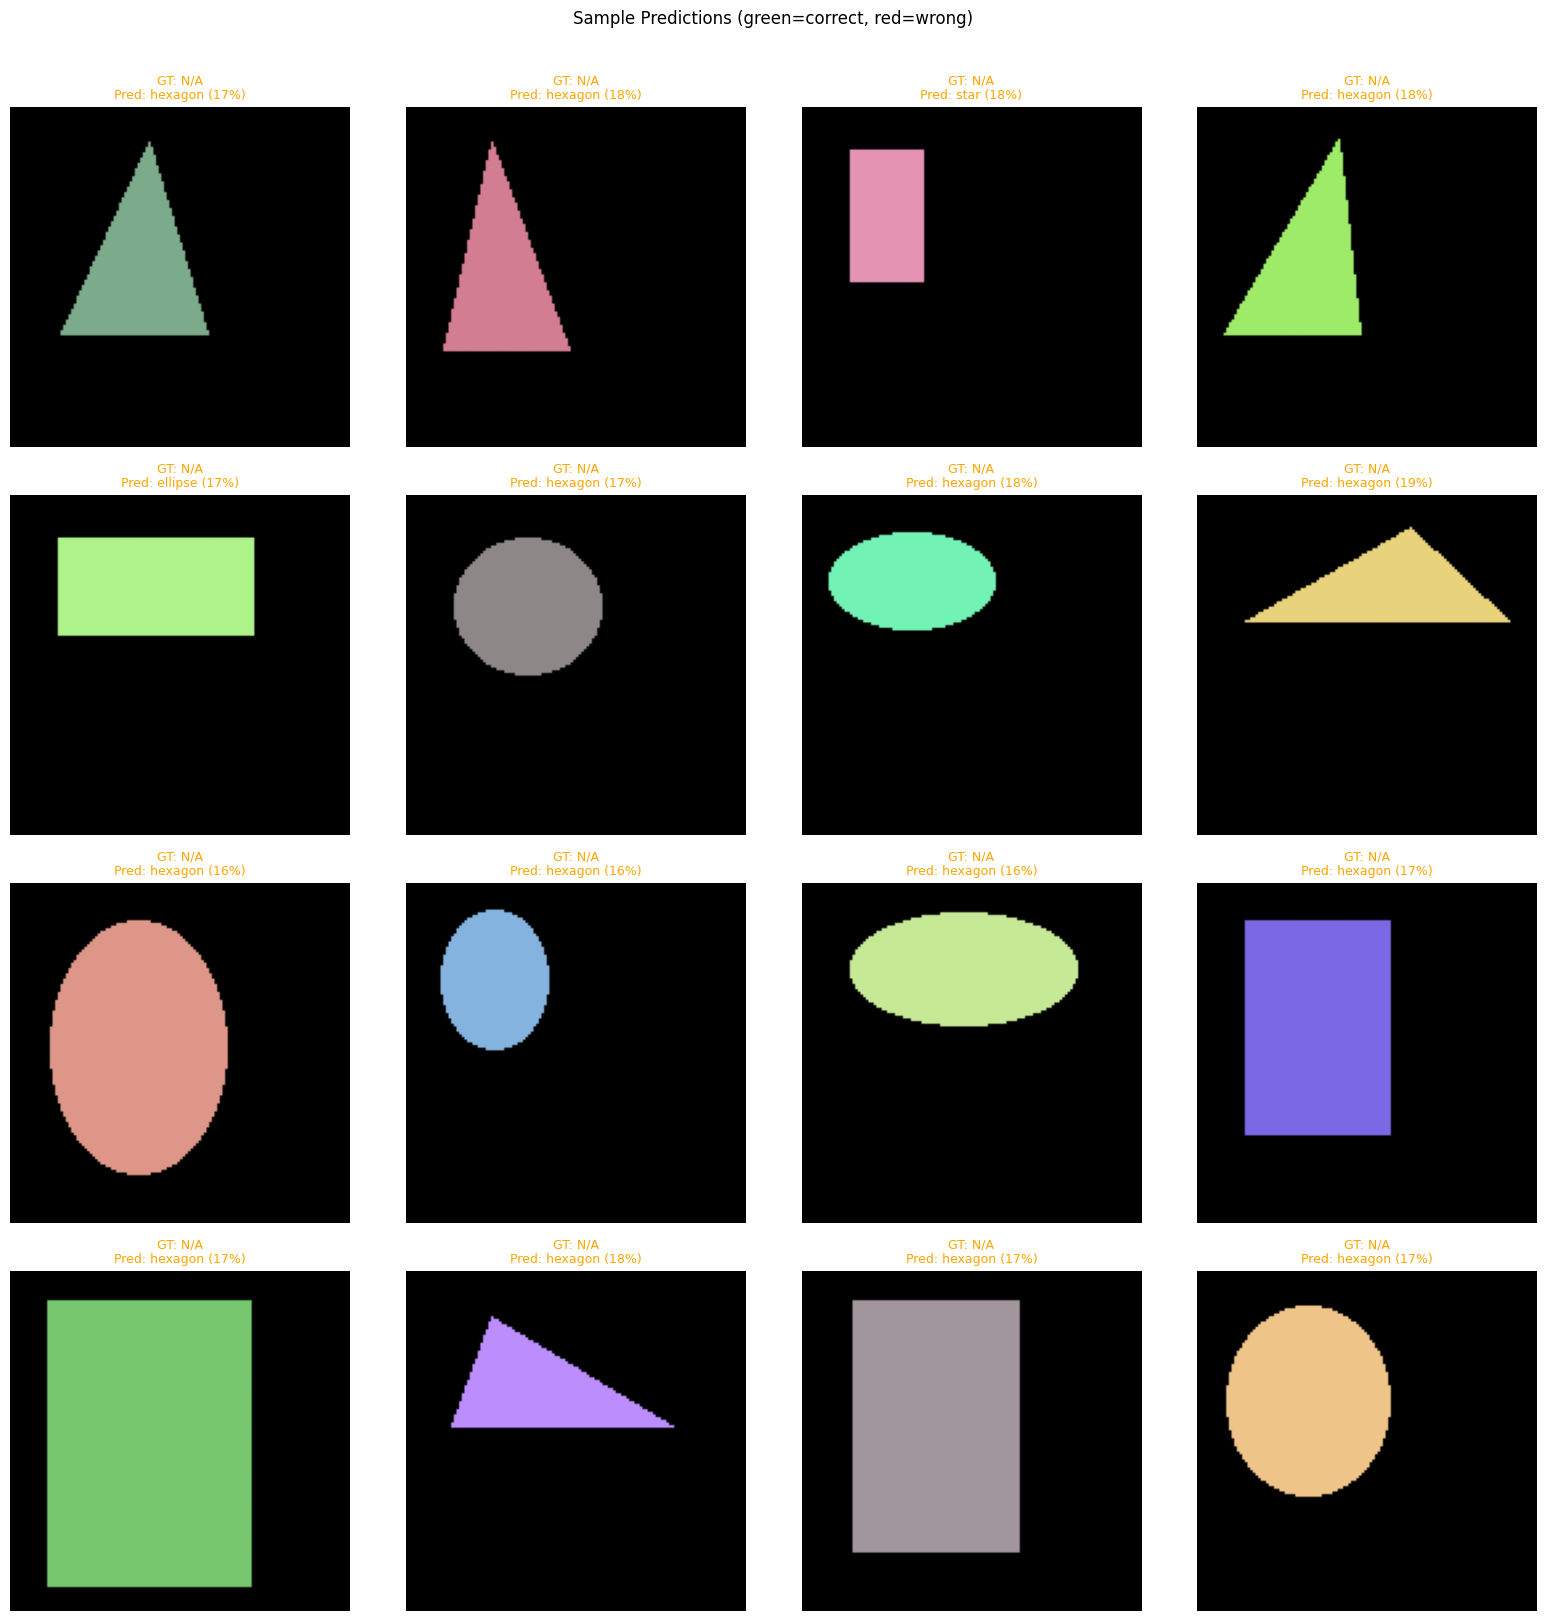

In [21]:
N_SHOW = min(16, len(results_df))
sample = results_df.sample(N_SHOW, random_state=42).reset_index(drop=True)
cols, rows = 4, (N_SHOW + 3) // 4
fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 4*rows))
axes = axes.flatten()

for i, row in sample.iterrows():
    try:
        axes[i].imshow(mpimg.imread(image_dir / row['image_name']))
    except Exception:
        axes[i].text(0.5, 0.5, 'error', ha='center', va='center')
    colour = 'green' if row['correct'] else ('red' if row['correct'] is False else 'orange')
    axes[i].set_title(f"GT: {row['ground_truth']}\nPred: {row['prediction']} ({row['confidence']:.0%})", color=colour, fontsize=9)
    axes[i].axis('off')

for j in range(i+1, len(axes)): axes[j].axis('off')
plt.suptitle('Sample Predictions (green=correct, red=wrong)', y=1.01)
plt.tight_layout()
plt.savefig('sample_predictions.png', dpi=150, bbox_inches='tight')
plt.show()


## 12. Save Results

In [22]:
results_df.to_csv(OUTPUT_CSV, index=False)
print(f"✅ Saved to {OUTPUT_CSV}")
results_df.tail(5)


✅ Saved to ./predictions.csv


,image_name,ground_truth,prediction,confidence,correct,p_circle,p_square,p_triangle,p_rectangle,p_pentagon,p_hexagon,p_star,p_ellipse
995,shape_995.png,N/A,hexagon,0.1561,None,0.1215,0.1033,0.1217,0.1305,0.0967,0.1561,0.1433,0.1268
996,shape_996.png,N/A,hexagon,0.1717,None,0.0815,0.0808,0.1206,0.1396,0.0964,0.1717,0.1592,0.1501
997,shape_997.png,N/A,hexagon,0.1773,None,0.0930,0.0752,0.1090,0.1586,0.1223,0.1773,0.1373,0.1272
998,shape_998.png,N/A,hexagon,0.1708,None,0.0872,0.0849,0.1074,0.1329,0.0914,0.1708,0.1644,0.1609
999,shape_999.png,N/A,hexagon,0.1776,None,0.0915,0.0848,0.1117,0.1547,0.0982,0.1776,0.1415,0.1399
